Software Support Ticket Resolution — Regression Analysis

# 1. Environment Setup & Data Exploration
In this step, we import the required Python libraries for data manipulation, visualization, regression modeling, and pipeline creation. 

We then load `lab_ticket_resolution.csv` and inspect its structure, checking:
- **Shape**: The total number of rows and columns.
- **Data Types**: Identifying numerical and categorical features.
- **Descriptive Statistics**: Summary measures (mean, min, max, std) for each variable.
- **Missing Values**: Ensuring there are no null values in the dataset.
- **First 5 Rows**: A quick preview of the tabular data.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("lab_ticket_resolution.csv")

# Display shape, data types, descriptive statistics, missing values, and first 5 rows
print("--- DATASET SHAPE ---")
print(df.shape)
print("\n--- DATA TYPES ---")
print(df.dtypes)
print("\n--- DESCRIPTIVE STATISTICS ---")
print(df.describe(include="all"))
print("\n--- MISSING VALUES ---")
print(df.isna().sum())
print("\n--- FIRST 5 ROWS ---")
print(df.head())

--- DATASET SHAPE ---
(240, 6)

--- DATA TYPES ---
ticket_id                 object
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

--- DESCRIPTIVE STATISTICS ---
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN     

# 2. Feature Selection & Train/Test Split
In this step, we define our target variable ($y$) and feature matrix ($X$):
- **Target ($y$)**: `resolution_hours` (the duration we aim to predict).
- **Features ($X$)**: `complexity_score`, `team_experience_years`, and `reopened`.
- **Exclusions**:
  - `ticket_id`: Excluded because it is a non-predictive identifier.
  - `lines_changed`: Excluded to avoid **data leakage**, as code lines changed can only be known *after* a ticket is resolved, not at prediction time.

We split the dataset into an **80% training set** and a **20% test set** with `random_state=42` to ensure reproducible results.

In [15]:
# Define target variable y and features X
X = df[['complexity_score', 'team_experience_years', 'reopened']]
y = df['resolution_hours']

# Split data into 80% training and 20% test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape:     {X_test.shape}")

Training set shape: (192, 3)
Test set shape:     (48, 3)


# 3. Baseline Model (Dummy Regressor)
We evaluate a simple baseline model using `DummyRegressor(strategy='mean')`. 

This model ignores all features and predicts the mean resolution time of the training data for every test instance. It provides a performance benchmark (floor) that any useful machine learning model must significantly beat.

In [16]:
# Fit DummyRegressor
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

# Calculate metrics
mse_dummy = mean_squared_error(y_test, y_pred_dummy)
print("--- DUMMY REGRESSOR BASELINE METRICS ---")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_dummy):.4f}")
print(f"MSE:  {mse_dummy:.4f}")
print(f"RMSE: {np.sqrt(mse_dummy):.4f}")
print(f"R2:   {r2_score(y_test, y_pred_dummy):.4f}")

--- DUMMY REGRESSOR BASELINE METRICS ---
MAE:  9.1140
MSE:  112.3109
RMSE: 10.5977
R2:   -0.0210


# 4. Multiple Linear Regression
We fit an Ordinary Least Squares (OLS) **Multiple Linear Regression** model using the three valid predictive features (`complexity_score`, `team_experience_years`, `reopened`).

We record its performance on the test set across MAE, MSE, RMSE, and $R^2$ to measure how well a standard linear relationship predicts ticket resolution hours.

In [17]:
# Fit Multiple Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# Calculate metrics
mse_lr = mean_squared_error(y_test, y_pred_lr)
print("--- MULTIPLE LINEAR REGRESSION METRICS ---")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_lr):.4f}")
print(f"MSE:  {mse_lr:.4f}")
print(f"RMSE: {np.sqrt(mse_lr):.4f}")
print(f"R2:   {r2_score(y_test, y_pred_lr):.4f}")

--- MULTIPLE LINEAR REGRESSION METRICS ---
MAE:  2.5905
MSE:  10.3629
RMSE: 3.2192
R2:   0.9058


# 5. Polynomial Feature Pipelines & Cross-Validation
We test whether introducing non-linear feature interactions improves predictions. 

Using scikit-learn pipelines with `PolynomialFeatures` and `StandardScaler`, we compare **Degree 2** and **Degree 3** polynomial expansions. Models are evaluated using **5-Fold Cross-Validation** on the training set to check for potential overfitting before testing on unseen test data.

In [18]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for deg in [2, 3]:
    poly_pipe = make_pipeline(PolynomialFeatures(degree=deg), StandardScaler(), LinearRegression())
    
    # 5-Fold Cross-Validation on training set
    cv_scores = cross_val_score(poly_pipe, X_train, y_train, cv=kf, scoring='neg_mean_squared_error')
    cv_mse = -cv_scores.mean()
    
    # Fit and evaluate on test set
    poly_pipe.fit(X_train, y_train)
    y_pred_poly = poly_pipe.predict(X_test)
    mse_poly = mean_squared_error(y_test, y_pred_poly)
    
    print(f"--- POLYNOMIAL REGRESSION (DEGREE {deg}) ---")
    print(f"5-Fold CV MSE: {cv_mse:.4f}")
    print(f"Test MAE:       {mean_absolute_error(y_test, y_pred_poly):.4f}")
    print(f"Test MSE:       {mse_poly:.4f}")
    print(f"Test RMSE:      {np.sqrt(mse_poly):.4f}")
    print(f"Test R2:        {r2_score(y_test, y_pred_poly):.4f}\n")

--- POLYNOMIAL REGRESSION (DEGREE 2) ---
5-Fold CV MSE: 12.4170
Test MAE:       2.7818
Test MSE:       12.6225
Test RMSE:      3.5528
Test R2:        0.8852

--- POLYNOMIAL REGRESSION (DEGREE 3) ---
5-Fold CV MSE: 13.1732
Test MAE:       2.8233
Test MSE:       13.1400
Test RMSE:      3.6249
Test R2:        0.8805



# 6. Regularization Pipelines (Ridge & Lasso)
To control model complexity and prevent potential overfitting from polynomial features, we apply **L2 Regularization (Ridge)** and **L1 Regularization (Lasso)**.

Each model pipeline incorporates `StandardScaler()` (essential for scale-sensitive penalties) and `PolynomialFeatures(degree=2)`. We perform grid search with 5-fold cross-validation (`GridSearchCV`) to find the optimal hyperparameter ($\alpha$) for both models.

In [19]:
# Ridge Regression Pipeline & Grid Search
ridge_pipe = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), Ridge())
ridge_grid = GridSearchCV(ridge_pipe, {'ridge__alpha': [0.1, 1.0, 10.0, 100.0]}, cv=kf, scoring='neg_mean_squared_error')
ridge_grid.fit(X_train, y_train)

best_ridge = ridge_grid.best_estimator_
y_pred_ridge = best_ridge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)

print("--- RIDGE REGRESSION RESULTS ---")
print(f"Best Alpha: {ridge_grid.best_params_}")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_ridge):.4f}")
print(f"MSE:  {mse_ridge:.4f}")
print(f"RMSE: {np.sqrt(mse_ridge):.4f}")
print(f"R2:   {r2_score(y_test, y_pred_ridge):.4f}\n")

# Lasso Regression Pipeline & Grid Search
lasso_pipe = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), Lasso(max_iter=10000))
lasso_grid = GridSearchCV(lasso_pipe, {'lasso__alpha': [0.001, 0.01, 0.1, 1.0, 10.0]}, cv=kf, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train, y_train)

best_lasso = lasso_grid.best_estimator_
y_pred_lasso = best_lasso.predict(X_test)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)

print("--- LASSO REGRESSION RESULTS ---")
print(f"Best Alpha: {lasso_grid.best_params_}")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_lasso):.4f}")
print(f"MSE:  {mse_lasso:.4f}")
print(f"RMSE: {np.sqrt(mse_lasso):.4f}")
print(f"R2:   {r2_score(y_test, y_pred_lasso):.4f}")

--- RIDGE REGRESSION RESULTS ---
Best Alpha: {'ridge__alpha': 0.1}
MAE:  2.7813
MSE:  12.6178
RMSE: 3.5522
R2:   0.8853

--- LASSO REGRESSION RESULTS ---
Best Alpha: {'lasso__alpha': 0.001}
MAE:  2.7803
MSE:  12.6100
RMSE: 3.5511
R2:   0.8854


# 7. Residual Analysis and Visual Evaluation
In this final step, we plot:
1. **Observed vs. Predicted Plot**: Checks how close predictions lie to the ideal $y = \hat{y}$ line.
2. **Residual Plot ($y - \hat{y}$ vs. $\hat{y}$)**: Checks for systematic errors, non-linear curvature, or heteroscedasticity (changing variance).

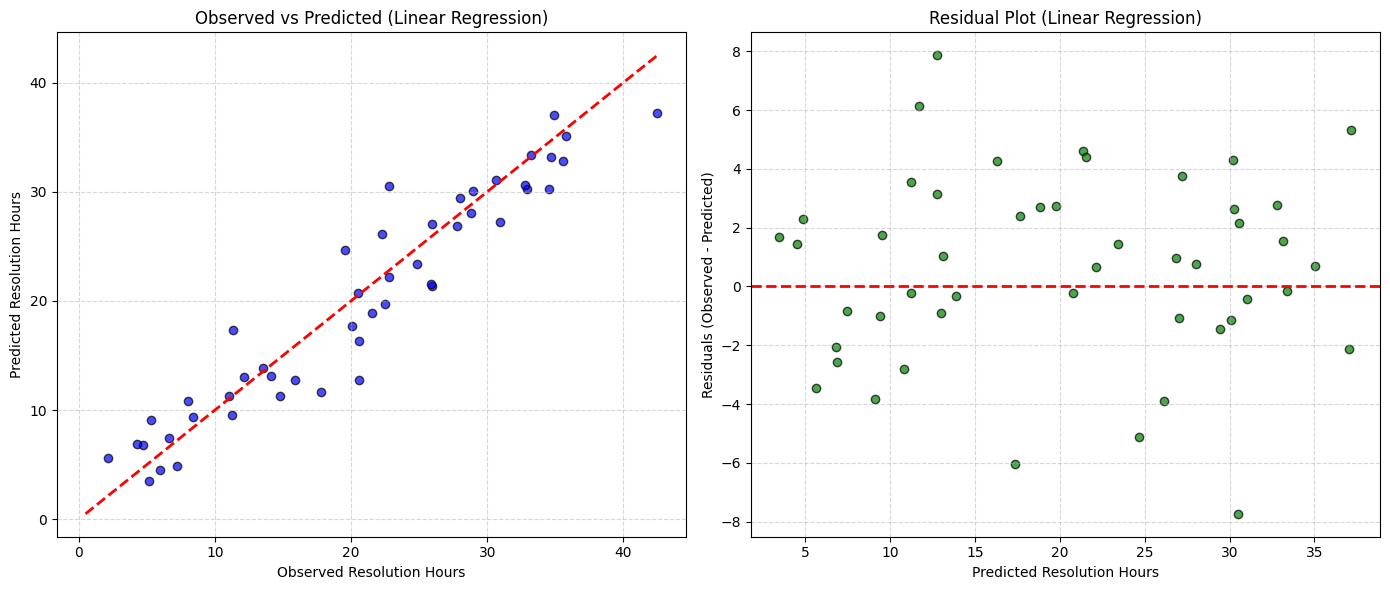

In [20]:
# Generate Observed vs Predicted and Residual plots for Linear Regression
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Observed vs Predicted
axes[0].scatter(y_test, y_pred_lr, alpha=0.7, color='blue', edgecolors='k')
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
axes[0].set_xlabel("Observed Resolution Hours")
axes[0].set_ylabel("Predicted Resolution Hours")
axes[0].set_title("Observed vs Predicted (Linear Regression)")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Residual Plot
residuals = y_test - y_pred_lr
axes[1].scatter(y_pred_lr, residuals, alpha=0.7, color='green', edgecolors='k')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel("Predicted Resolution Hours")
axes[1].set_ylabel("Residuals (Observed - Predicted)")
axes[1].set_title("Residual Plot (Linear Regression)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# %% [markdown]
# ## Tasks 9–17 — Recommendation and analysis answers
#
# ### Task 9. Which model would you choose?
#
# Choose the model with the best held-out test metrics, while also considering
# simplicity and interpretability. In this dataset, linear regression is a strong
# starting point if it beats the mean baseline and polynomial models do not improve
# performance. Ridge is also reasonable if a regularized model is preferred.
# Because the dataset is synthetic, validate on representative real ticket data
# before deployment.
#
# ### Task 10. Why is the mean baseline useful?
#
# It provides a simple reference that ignores all input features. A more complex
# model should outperform this baseline; otherwise, the selected features may not
# add useful predictive information.
#
# ### Task 11. Which model has the lowest MAE and RMSE? Are they the same?
#
# Use the `metrics` table above to identify the lowest MAE and RMSE. MAE measures
# average absolute error, while RMSE gives larger errors extra weight. Therefore,
# the model with the lowest MAE need not also have the lowest RMSE.
#
# ### Task 12. Did polynomial features improve validation performance?
#
# Compare degree-2 and degree-3 cross-validation MAE values printed above and compare
# their test metrics with linear regression. If a higher degree performs worse,
# the extra complexity is not helping. A large gap between training/CV and test
# performance can be a warning sign of overfitting.
#
# ### Task 13. How did regularization affect performance and coefficients?
#
# Compare Ridge and Lasso metrics with ordinary linear regression. Ridge shrinks
# coefficients toward zero; Lasso can shrink some coefficients exactly to zero.
# If test scores are almost unchanged, regularization had little effect on prediction
# accuracy for this dataset.
#
# ### Task 14. Why is scaling included in Ridge/Lasso?
#
# Regularization penalizes coefficient size. Scaling makes features comparable so
# the penalty is not dominated by a feature simply because it uses larger units.
#
# ### Task 15. Identify a potential leakage issue and explain the handling.
#
# `lines_changed` is likely measured during/after the fix, so it would not be
# available at ticket intake and could leak future information. It was excluded.
# `reopened` may also only be known after a resolution attempt, so it was excluded.
#
# ### Task 16. Is a random split suitable for tickets collected over years or
# repeated customers/teams?
#
# Not always. For forecasting future tickets, use a time-based split where the
# training data precedes the test data. If tickets repeat within customers or teams,
# use group-aware splitting so related records do not appear in both sets.
#
# ### Task 17. What additional tests are needed before deployment?
#
# Test on newer, representative real tickets; use time/group-aware evaluation when
# appropriate; inspect residuals and errors by complexity/team; investigate outliers;
# check data quality and feature availability; assess prediction uncertainty; and
# monitor performance and data drift after deployment.
#
# %% [markdown]
# ## Final conclusion
#
# Use the metrics table and plots as evidence. Prefer a simple model when its
# performance is similar to more complex models. These results describe only the
# supplied synthetic dataset and must not be assumed to generalize to a real
# support organization without further validation.
